In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load Week 1 datasets
sold = pd.read_csv("../output/combined_sold_residential.csv", low_memory=False)
listings = pd.read_csv("../output/combined_listings_residential.csv", low_memory=False)

# Check dataset size and structure
print("Sold:", sold.shape)
print("Listings:", listings.shape)

sold.info()
print(sold.columns.tolist())

Sold: (414054, 84)
Listings: (547162, 84)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414054 entries, 0 to 414053
Data columns (total 84 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Flooring                      265465 non-null  object 
 1   ViewYN                        378790 non-null  object 
 2   WaterfrontYN                  259 non-null     object 
 3   BasementYN                    8102 non-null    object 
 4   PoolPrivateYN                 378388 non-null  object 
 5   OriginalListPrice             413298 non-null  float64
 6   ListingKey                    414054 non-null  int64  
 7   ListAgentEmail                412989 non-null  object 
 8   CloseDate                     414054 non-null  object 
 9   ClosePrice                    414052 non-null  float64
 10  ListAgentFirstName            410945 non-null  object 
 11  ListAgentLastName             414012 non-null  object 
 12  La

In [2]:
# Confirm Residential filtering
print("Sold property types:", sold["PropertyType"].unique())
print("Listing property types:", listings["PropertyType"].unique())

# Create missing value reports
sold_missing = pd.DataFrame({
    "Missing Count": sold.isnull().sum(),
    "Missing Percent": sold.isnull().mean() * 100
})

listing_missing = pd.DataFrame({
    "Missing Count": listings.isnull().sum(),
    "Missing Percent": listings.isnull().mean() * 100
})

# Sort by missing percentage
sold_missing = sold_missing.sort_values("Missing Percent", ascending=False)
listing_missing = listing_missing.sort_values("Missing Percent", ascending=False)

print("Sold missing values:")
print(sold_missing.head(20))

print("Listing missing values:")
print(listing_missing.head(20))

Sold property types: ['Residential']
Listing property types: ['Residential']
Sold missing values:
                              Missing Count  Missing Percent
TaxYear                              414054       100.000000
FireplacesTotal                      414054       100.000000
TaxAnnualAmount                      414054       100.000000
AboveGradeFinishedArea               414054       100.000000
ElementarySchoolDistrict             414054       100.000000
BusinessType                         414054       100.000000
CoveredSpaces                        414054       100.000000
MiddleOrJuniorSchoolDistrict         414054       100.000000
WaterfrontYN                         413795        99.937448
BelowGradeFinishedArea               411652        99.419882
BasementYN                           405952        98.043250
LotSizeDimensions                    393945        95.143387
BuilderName                          393790        95.105952
BuildingAreaTotal                    385055     

In [3]:
# Find columns with more than 90% missing values
sold_high_missing = sold_missing[sold_missing["Missing Percent"] > 90]
listing_high_missing = listing_missing[listing_missing["Missing Percent"] > 90]

print("Sold columns above 90% missing:")
print(sold_high_missing)

print("Listing columns above 90% missing:")
print(listing_high_missing)

Sold columns above 90% missing:
                              Missing Count  Missing Percent
TaxYear                              414054       100.000000
FireplacesTotal                      414054       100.000000
TaxAnnualAmount                      414054       100.000000
AboveGradeFinishedArea               414054       100.000000
ElementarySchoolDistrict             414054       100.000000
BusinessType                         414054       100.000000
CoveredSpaces                        414054       100.000000
MiddleOrJuniorSchoolDistrict         414054       100.000000
WaterfrontYN                         413795        99.937448
BelowGradeFinishedArea               411652        99.419882
BasementYN                           405952        98.043250
LotSizeDimensions                    393945        95.143387
BuilderName                          393790        95.105952
BuildingAreaTotal                    385055        92.996324
CoBuyerAgentFirstName                376429        90

In [4]:
# Key numeric fields
numeric_columns = ["ClosePrice", "LivingArea", "DaysOnMarket"]

# Convert to numeric
for column in numeric_columns:
    sold[column] = pd.to_numeric(sold[column], errors="coerce")

# Calculate summary statistics
numeric_summary = sold[numeric_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(numeric_summary)

         ClosePrice    LivingArea   DaysOnMarket
count  4.140520e+05  4.138200e+05  414054.000000
mean   1.193864e+06  1.903791e+03      37.355123
std    6.290122e+06  2.647620e+04      53.592461
min    0.000000e+00  0.000000e+00    -288.000000
25%    5.750000e+05  1.248000e+03       8.000000
50%    8.230000e+05  1.642000e+03      18.000000
75%    1.300000e+06  2.219000e+03      48.000000
90%    2.065000e+06  2.977000e+03      94.000000
95%    2.850000e+06  3.559050e+03     132.000000
99%    5.575000e+06  5.282000e+03     231.000000
max    9.895000e+08  1.702132e+07   12430.000000


In [ ]:
# Save reports
Path("../reports").mkdir(exist_ok=True)

sold_missing.to_csv("../reports/sold_missing_report.csv")
listing_missing.to_csv("../reports/listings_missing_report.csv")
numeric_summary.to_csv("../reports/numeric_summary.csv")

print("Week 2 initial analysis saved!")

## Additional Numeric Distribution Review

Review all nine housing metrics to identify unusual values and potential data quality issues.

,ClosePrice,ListPrice,OriginalListPrice,LivingArea,LotSizeAcres,BedroomsTotal,BathroomsTotalInteger,DaysOnMarket,YearBuilt
count,4.140520e+05,4.140540e+05,4.132980e+05,4.138200e+05,3.815190e+05,414043.000000,413985.000000,414054.000000,413682.000000
mean,1.193864e+06,1.140462e+06,1.225401e+06,1.903791e+03,6.630318e+01,3.201056,2.534771,37.355123,1978.580477
std,6.290122e+06,1.359497e+06,6.709938e+06,2.647620e+04,1.599818e+04,1.067103,1.134152,53.592461,26.278227
min,0.000000e+00,5.250000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,-288.000000,1776.000000
25%,5.750000e+05,5.761670e+05,5.850000e+05,1.248000e+03,1.200000e-01,3.000000,2.000000,8.000000,1960.000000
50%,8.230000e+05,8.150000e+05,8.250000e+05,1.642000e+03,1.664000e-01,3.000000,2.000000,18.000000,1979.000000
75%,1.300000e+06,1.295000e+06,1.299000e+06,2.219000e+03,2.730000e-01,4.000000,3.000000,48.000000,1999.000000
90%,2.065000e+06,1.999000e+06,2.068000e+06,2.977000e+03,1.047400e+00,4.000000,4.000000,94.000000,2016.000000
95%,2.850000e+06,2.850000e+06,2.899999e+06,3.559050e+03,2.820200e+00,5.000000,4.000000,132.000000,2022.000000
99%,5.575000e+06,5.700000e+06,5.995000e+06,5.282000e+03,1.083350e+01,6.000000,6.000000,231.000000,2025.000000


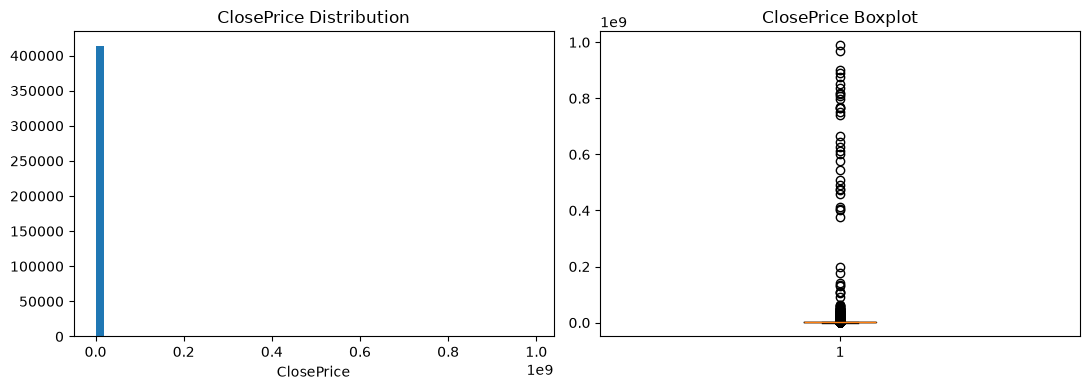

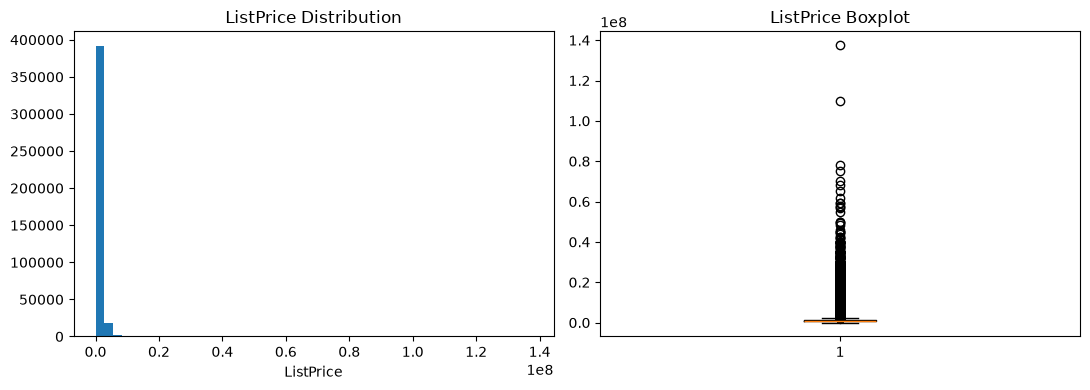

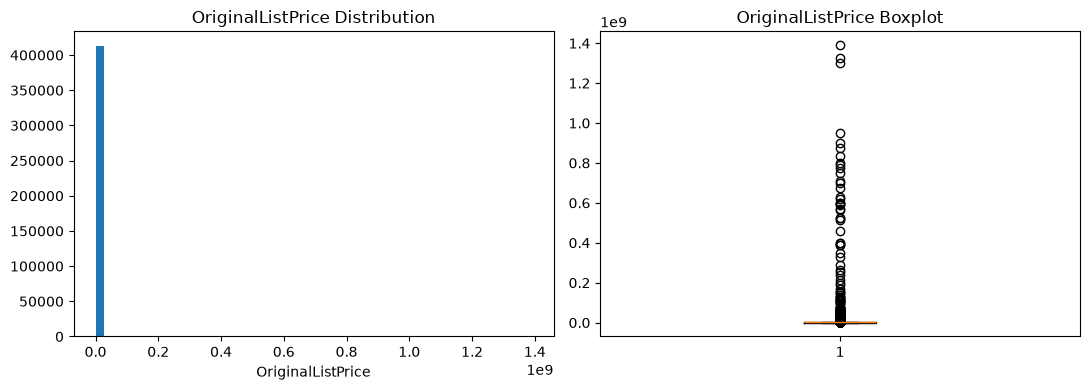

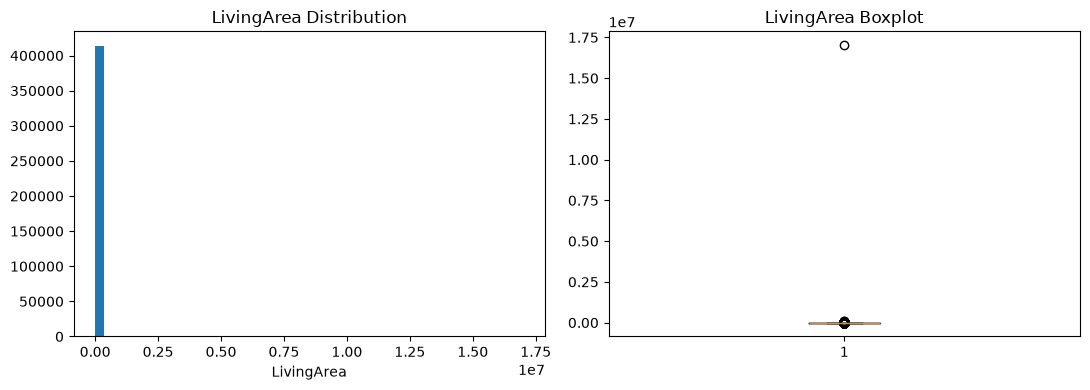

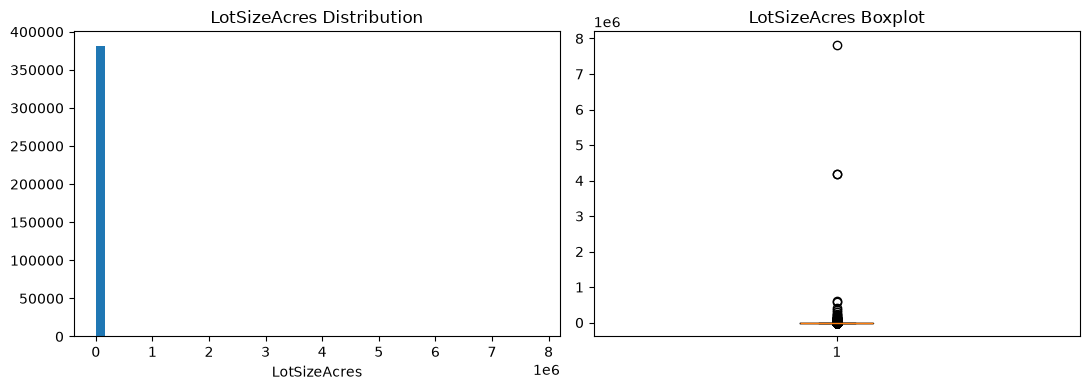

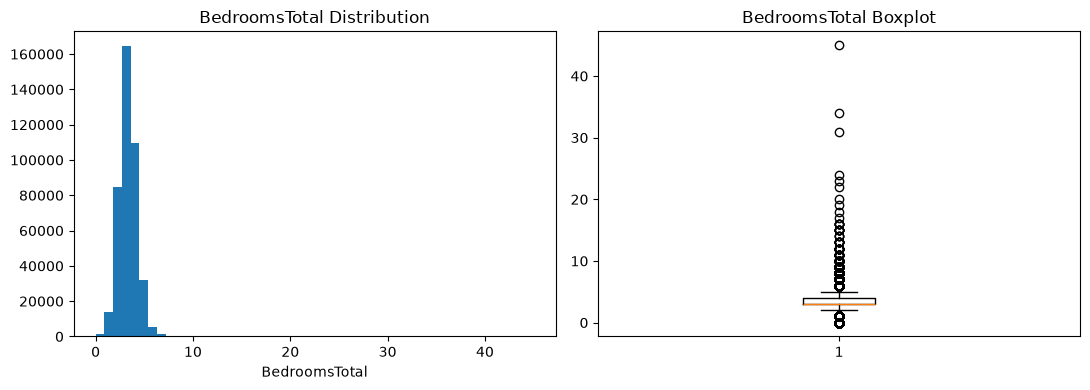

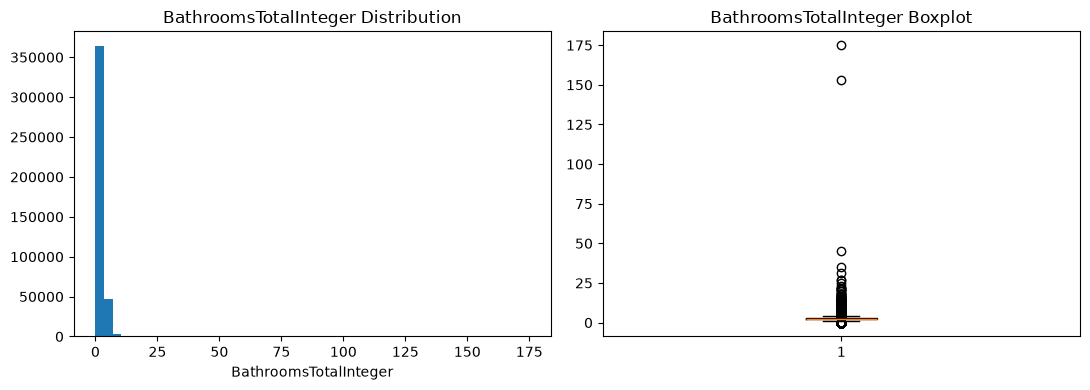

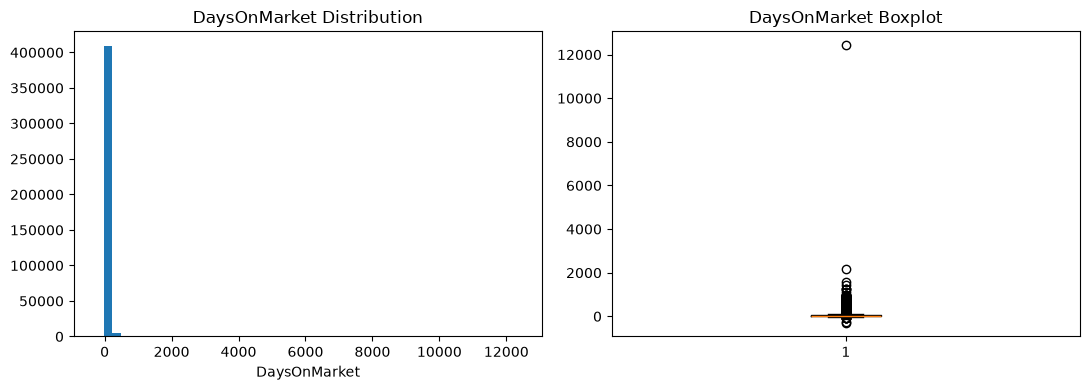

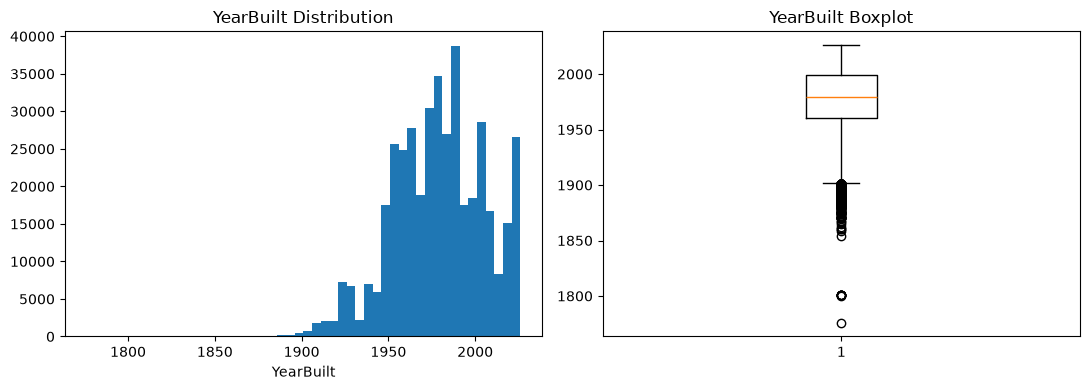

In [6]:
#loking at spread of prices, bedrooms, home sizes, and other housing metrics to find unusual records


# Nine numeric fields required by the handbook
market_fields = [
    "ClosePrice",
    "ListPrice",
    "OriginalListPrice",
    "LivingArea",
    "LotSizeAcres",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "DaysOnMarket",
    "YearBuilt"
]

# Convert fields to numeric values
for column in market_fields:
    sold[column] = pd.to_numeric(sold[column], errors="coerce")

# Calculate summary statistics
market_summary = sold[market_fields].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(market_summary)

# Create histograms and boxplots
for column in market_fields:
    values = sold[column].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].hist(values, bins=50)
    axes[0].set_title(column + " Distribution")
    axes[0].set_xlabel(column)

    axes[1].boxplot(values)
    axes[1].set_title(column + " Boxplot")

    plt.tight_layout()
    plt.show()

## Data Quality Checks

Identify potential outliers and decide which missing-data columns should be retained or reviewed for removal.

In [7]:
# Check unusual values
print("Close prices at or below $0:",
      (sold["ClosePrice"] <= 0).sum())

print("Living areas at or below 0:",
      (sold["LivingArea"] <= 0).sum())

print("Negative days on market:",
      (sold["DaysOnMarket"] < 0).sum())

print("Year built after 2026:",
      (sold["YearBuilt"] > 2026).sum())

# Review columns with over 90% missing data
print("\nSold columns above 90% missing:")
display(sold_high_missing)

print("\nListing columns above 90% missing:")
display(listing_high_missing)

# Keep important fields even if they contain missing values
core_fields = [
    "ClosePrice", "ListPrice", "LivingArea",
    "DaysOnMarket", "CloseDate",
    "ListingContractDate", "PropertyType"
]

# Identify non-core columns for possible removal
review_for_removal = [
    column for column in sold_high_missing.index
    if column not in core_fields
]

print("\nNon-core columns to review for removal:")
print(review_for_removal)

Close prices at or below $0: 1
Living areas at or below 0: 150
Negative days on market: 48
Year built after 2026: 0

Sold columns above 90% missing:


,Missing Count,Missing Percent
TaxYear,414054,100.000000
FireplacesTotal,414054,100.000000
TaxAnnualAmount,414054,100.000000
AboveGradeFinishedArea,414054,100.000000
ElementarySchoolDistrict,414054,100.000000
BusinessType,414054,100.000000
CoveredSpaces,414054,100.000000
MiddleOrJuniorSchoolDistrict,414054,100.000000
WaterfrontYN,413795,99.937448
BelowGradeFinishedArea,411652,99.419882



Listing columns above 90% missing:


,Missing Count,Missing Percent
TaxYear,547162,100.000000
TaxAnnualAmount,547162,100.000000
AboveGradeFinishedArea,547162,100.000000
FireplacesTotal,547162,100.000000
ElementarySchoolDistrict,547162,100.000000
BusinessType,547162,100.000000
CoveredSpaces,547162,100.000000
MiddleOrJuniorSchoolDistrict,547162,100.000000
BelowGradeFinishedArea,544075,99.435816
CoBuyerAgentFirstName,533466,97.496902



Non-core columns to review for removal:
['TaxYear', 'FireplacesTotal', 'TaxAnnualAmount', 'AboveGradeFinishedArea', 'ElementarySchoolDistrict', 'BusinessType', 'CoveredSpaces', 'MiddleOrJuniorSchoolDistrict', 'WaterfrontYN', 'BelowGradeFinishedArea', 'BasementYN', 'LotSizeDimensions', 'BuilderName', 'BuildingAreaTotal', 'CoBuyerAgentFirstName']


In [8]:
# Compare sold prices against list prices
valid_prices = sold[
    (sold["ClosePrice"] > 0) &
    (sold["ListPrice"] > 0)
].copy()

above_list = (valid_prices["ClosePrice"] > valid_prices["ListPrice"]).mean() * 100
below_list = (valid_prices["ClosePrice"] < valid_prices["ListPrice"]).mean() * 100
at_list = (valid_prices["ClosePrice"] == valid_prices["ListPrice"]).mean() * 100

print(f"Sold above list price: {above_list:.2f}%")
print(f"Sold below list price: {below_list:.2f}%")
print(f"Sold at list price: {at_list:.2f}%")

# Check date consistency
close_dates = pd.to_datetime(sold["CloseDate"], errors="coerce")
listing_dates = pd.to_datetime(sold["ListingContractDate"], errors="coerce")

invalid_dates = (close_dates < listing_dates).sum()

print("Close dates before listing dates:", invalid_dates)

# Compare median sold prices by county
if "CountyOrParish" in sold.columns:
    county_prices = sold[sold["ClosePrice"] > 0].groupby(
        "CountyOrParish"
    )["ClosePrice"].median().sort_values(ascending=False)

    print("\nMedian sold price by county:")
    display(county_prices.head(10))

Sold above list price: 40.10%
Sold below list price: 42.55%
Sold at list price: 17.35%
Close dates before listing dates: 61

Median sold price by county:


CountyOrParish
Del Norte        2485000.0
San Mateo        1700000.0
Santa Clara      1600000.0
Santa Cruz       1200000.0
San Francisco    1198950.0
Orange           1175000.0
Marin            1165000.0
Alameda          1134000.0
Alpine           1100000.0
Other County     1100000.0
Name: ClosePrice, dtype: float64

In [9]:
# Save reports
Path("../reports").mkdir(exist_ok=True)
Path("../output").mkdir(exist_ok=True)

market_summary.to_csv("../reports/week2_numeric_summary.csv")
sold_missing.to_csv("../reports/sold_missing_report.csv")
listing_missing.to_csv("../reports/listings_missing_report.csv")

# Save filtered Residential datasets
sold.to_csv("../output/week2_sold_residential.csv", index=False)
listings.to_csv("../output/week2_listings_residential.csv", index=False)

print("Week 2 reports and datasets saved!")

Week 2 reports and datasets saved!


## Weeks 2–3: Data Exploration & Validation

### Goal
Check data quality, missing values, and housing market trends before further analysis.

### Findings
- Analyzed 414,054 sold records and 547,162 listing records, each with 84 columns.
- Both datasets contain only Residential properties.
- 15 sold columns and 13 listing columns have over 90% missing values.
- Median sold price: $823,000; average sold price: approximately $1.19 million.
- Median living area: 1,642 sq ft.
- Median days on market: 18 days; average: 37 days.
- 40.10% of homes sold above list price, 42.55% below, and 17.35% at list price.
- Del Norte ($2.49M), San Mateo ($1.70M), and Santa Clara ($1.60M) had the highest median sold prices in the county summary.
- Found potential data quality issues:
  - 48 records with negative days on market.
  - 150 records with zero or negative living area.
  - 61 records with close dates before listing dates.
  - 1 record with a zero or negative close price.

### Business Takeaway
The median sold price of $823K is more representative of a typical property than the $1.19M average, which may be influenced by extreme prices. Homes generally sold within a few weeks, and slightly more sold below list price than above. Data quality issues should be reviewed before using the dataset for market reporting.

### Note
- Columns with over 90% missing values should be reviewed for removal, while important market fields should be retained when possible.
- Extreme values and inconsistent dates were flagged but not removed.
- County comparisons may be affected by small sample sizes and should be validated before drawing conclusions.